# Global Solution — Segurança pública inteligente em São Paulo
## Classificação de ocorrências (Roubo × Furto) com MLP

**Objetivo.** Dadas as características de uma ocorrência **já registrada (ou hipotética)** de subtração de celular na capital paulista, estimar se ela é mais compatível com **roubo** ou **furto**.

> ⚠️ O modelo **não** prevê se um crime vai acontecer, nem o risco em um local/horário. A saída é a probabilidade de a ocorrência descrita ser da classe *roubo* (ou *furto*), **dado que ela ocorreu**.

**Fonte dos dados:** SSP-SP — Portal de Estatísticas → Consultas → Bases de Dados → *Celulares Subtraídos 2025* (https://www.ssp.sp.gov.br/estatistica/consultas). Período: boletins de 2025 (arquivo `CelularesSubtraidos_2025`). Para obter: baixar o arquivo no portal e salvá-lo como `dados/CelularesSubtraidos_2025.csv`.




In [12]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, classification_report, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

# Pastas de saída (usadas pela aplicação web e pelo relatório)
ARTEFATOS = 'artefatos'; FIGURAS = os.path.join(ARTEFATOS, 'figuras')
os.makedirs(FIGURAS, exist_ok=True)

# Procura o CSV baixado da SSP-SP
candidatos = ['dados/CelularesSubtraidos_2025.csv', 'CelularesSubtraidos_2025.csv',
              '/content/CelularesSubtraidos_2025.csv', '/mnt/user-data/uploads/CelularesSubtraidos_2025.csv']
CAMINHO = next(c for c in candidatos if os.path.exists(c))
print('Usando:', CAMINHO)

Usando: CelularesSubtraidos_2025.csv


## 1. Carga e exploração inicial

In [13]:
df = pd.read_csv(CAMINHO, sep=';', encoding='latin1', low_memory=False)
print(f"Total de registros originais: {len(df):,} | colunas: {df.shape[1]}")
print(df.columns.tolist())
print("\nNatureza das ocorrências (RUBRICA) — 5 mais frequentes:")
print(df['RUBRICA'].value_counts().head(5))

Total de registros originais: 383,635 | colunas: 55
['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CIA', 'CD_IBGE

## 2. Recorte, rótulo e atributos

- **Recorte geográfico:** utilizado `NOME_MUNICIPIO_CIRC = São Paulo`, que identifica onde o crime aconteceu, e não onde o boletim foi registrado.
- **Duplicidades:** mantida apenas uma linha por BO, pois um mesmo registro pode apresentar vários itens.
- **Classificação:** `RUBRICA`: 0 = furto e 1 = roubo. Outras naturezas foram excluídas por não fazerem parte do objetivo. Essa coluna não é usada como entrada do modelo.
- **Atributos utilizados:** bairro e logradouro (localização), período e dia da semana (tempo), subtipo do local e marca do celular (características da ocorrência).
- **Atributos excluídos:** informações que poderiam revelar antecipadamente a classificação do crime, dados do procedimento policial e identificadores pessoais ou geográficos.
- **Período do dia:** calculado a partir do horário da ocorrência. Quando ele não está disponível, utiliza-se `DESCR_PERIODO`. Assim, evitamos que dados ausentes criem padrões artificiais que prejudiquem a classificação.

In [14]:
# --- Recorte geográfico + um registro por BO ---
df_sp = df[df['NOME_MUNICIPIO_CIRC'].astype(str).str.upper().isin(['S.PAULO', 'SÃO PAULO', 'SAO PAULO'])].copy()
n_sp_linhas = len(df_sp)
df_sp = df_sp.drop_duplicates(subset=['NOME_DELEGACIA', 'ANO_BO', 'NUM_BO'])

# --- Rótulo (0 = Furto, 1 = Roubo) ---
d = df_sp[df_sp['RUBRICA'].isin(['Roubo (art. 157)', 'Furto (art. 155)'])].copy()
d['ALVO'] = d['RUBRICA'].map({'Furto (art. 155)': 0, 'Roubo (art. 157)': 1})

# --- Período unificado: hora -> período; DESCR_PERIODO como reserva ---
hora = pd.to_numeric(d['HORA_OCORRENCIA'].astype(str).str.extract(r'^(\d{1,2})')[0], errors='coerce')
periodo_hora = np.select([hora < 6, hora < 12, hora < 18], ['De madrugada', 'Pela manhã', 'A tarde'], default='A noite')
d['PERIODO'] = np.where(hora.notna(), periodo_hora, d['DESCR_PERIODO'])

# --- Dia da semana do fato ---
data = pd.to_datetime(d['DATA_OCORRENCIA_BO'], format='%d/%m/%Y', errors='coerce')
d['DIA_SEMANA'] = data.dt.dayofweek.map({0:'Segunda',1:'Terça',2:'Quarta',3:'Quinta',4:'Sexta',5:'Sábado',6:'Domingo'})

# --- Tratamento de ausentes ---
ATRIBUTOS_BRUTOS = {'BAIRRO': 'BAIRRO', 'LOGRADOURO': 'LOGRADOURO', 'PERIODO': 'PERIODO',
                    'SUBLOCAL': 'DESCR_SUBTIPOLOCAL', 'MARCA': 'MARCA_OBJETO', 'DIA_SEMANA': 'DIA_SEMANA'}
# Ausentes ANTES do preenchimento (período já unificado hora/DESCR_PERIODO)
ausentes = pd.Series({nome: d[col].isna().mean() for nome, col in ATRIBUTOS_BRUTOS.items()})
d_orig = d.copy()
for nome, col in ATRIBUTOS_BRUTOS.items():
    d[nome] = d_orig[col].fillna('NÃO INFORMADO').astype(str).str.strip().replace('', 'NÃO INFORMADO')

print(f"Linhas em SP (fato): {n_sp_linhas:,} | após 1 linha por BO: {len(df_sp):,} | Roubo/Furto: {len(d):,}")
print("\nDistribuição original das classes:")
print(d['ALVO'].map({0: 'Furto', 1: 'Roubo'}).value_counts())
print("\nProporção de valores ausentes por atributo (antes do preenchimento; ausente -> 'NÃO INFORMADO'):")
print(ausentes.round(4))

Linhas em SP (fato): 216,287 | após 1 linha por BO: 185,088 | Roubo/Furto: 160,024

Distribuição original das classes:
ALVO
Furto    101436
Roubo     58588
Name: count, dtype: int64

Proporção de valores ausentes por atributo (antes do preenchimento; ausente -> 'NÃO INFORMADO'):
BAIRRO        0.0024
LOGRADOURO    0.0000
PERIODO       0.0000
SUBLOCAL      0.0000
MARCA         0.0000
DIA_SEMANA    0.0000
dtype: float64


## 3. Exploração: o que diferencia roubo de furto nos atributos?

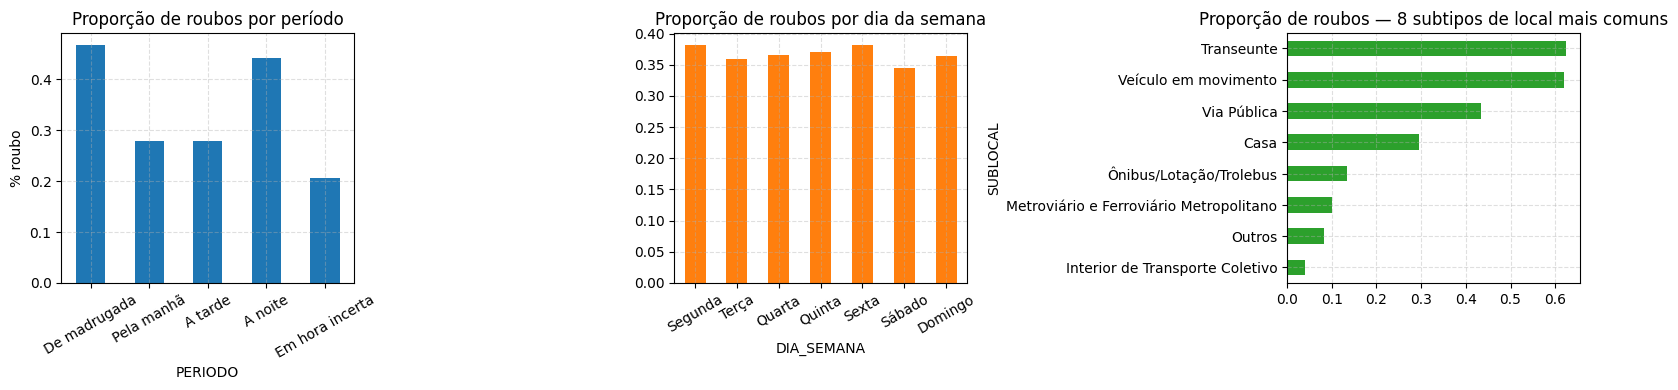

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ordem_p = ['De madrugada', 'Pela manhã', 'A tarde', 'A noite', 'Em hora incerta']
d.groupby('PERIODO')['ALVO'].mean().reindex(ordem_p).dropna().plot.bar(ax=axes[0], color='#1f77b4')
axes[0].set_title('Proporção de roubos por período'); axes[0].set_ylabel('% roubo'); axes[0].tick_params(axis='x', rotation=30)
ordem_d = ['Segunda','Terça','Quarta','Quinta','Sexta','Sábado','Domingo']
d.groupby('DIA_SEMANA')['ALVO'].mean().reindex(ordem_d).dropna().plot.bar(ax=axes[1], color='#ff7f0e')
axes[1].set_title('Proporção de roubos por dia da semana'); axes[1].tick_params(axis='x', rotation=30)
top_loc = d['SUBLOCAL'].value_counts().head(8).index
d[d['SUBLOCAL'].isin(top_loc)].groupby('SUBLOCAL')['ALVO'].mean().sort_values().plot.barh(ax=axes[2], color='#2ca02c')
axes[2].set_title('Proporção de roubos — 8 subtipos de local mais comuns')
for a in axes: a.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout(); plt.savefig(os.path.join(FIGURAS, 'eda_atributos.png'), dpi=130); plt.show()

### Interpretação da análise exploratória

Os dados são anteriores ao balanceamento: **36,6% são roubos e 63,4% furtos**.

1. **Período do dia:** à noite (44,3%) e de madrugada (46,8%) há maior proporção de roubos. Pela manhã (28%) e à tarde (27,8%), predominam os furtos.

2. **Dia da semana:** apresenta pouca diferença entre as classes, com roubos variando de 34,5% a 38,2%. Portanto, tem menor poder de separação.

3. **Tipo de local:** apresenta diferenças mais expressivas. Roubos predominam em situações de abordagem direta, como transeunte (62,4%) e veículo em movimento (61,9%). Já nos transportes coletivos predominam os furtos.

4. **Marca do celular:** possui pouca influência aparente, com proporções de roubo próximas à média geral.

**Implicação para o modelo:** período e tipo de local apresentam maior relação com a classificação. Entretanto, como nenhum atributo separa completamente as classes, esperamos um desempenho moderado, próximo de 70% de acurácia.

## 4. Balanceamento e divisão **70% / 15% / 15%**

1. **Balanceamento:** usamos **todos** os roubos e o mesmo número de furtos sorteados (*undersampling*, `random_state=42`). Assim, acurácia, precision e recall são comparáveis e a classe majoritária não domina o treino.
2. **Divisão (regra crítica):** dois `train_test_split` estratificados em sequência:
   - 1ª divisão: `test_size=0.30` → 70% treino e 30% temporário;
   - 2ª divisão: o temporário é dividido ao meio (`test_size=0.50`) → 15% validação e 15% teste.
3. **Sem vazamento no pré-processamento:** a lista de categorias frequentes (bairros, logradouros, subtipos, marcas) e as colunas do One-Hot são definidas **só com o treino**. Categorias raras/desconhecidas viram `OUTROS`.
4. **Escalonamento:** as entradas são One-Hot (0/1), já na mesma escala; não há variável numérica contínua, então não é necessário `StandardScaler`.

### 4.1. Engenharia de Features e Prevenção de Data Leakage
Para garantir a integridade matemática do modelo, adotei uma postura defensiva no pré-processamento. Variáveis muito óbvias (como `DESCR_CONDUTA`) foram removidas para evitar *Data Leakage* — ou seja, impedir que a rede neural recebesse a resposta "de bandeja" antes de prever.

Além disso, a divisão estratificada (70/15/15) e a aplicação do *One-Hot Encoding* foram feitas com rigor: o encoder aprendeu as categorias **apenas** com os dados de treino. Categorias não mapeadas que surgirem no teste são agrupadas como `OUTROS`, simulando exatamente o comportamento robusto que a API precisará ter em produção no Streamlit ao receber dados de usuários reais.

In [16]:
# --- 1) Balanceamento ---
n_classe = d['ALVO'].value_counts().min()
df_bal = pd.concat([d[d['ALVO'] == 1].sample(n_classe, random_state=SEED),
                    d[d['ALVO'] == 0].sample(n_classe, random_state=SEED)]).sample(frac=1, random_state=SEED).reset_index(drop=True)

# --- 2) Divisão 70/15/15 (estratificada) sobre o DataFrame ---
df_treino, df_temp = train_test_split(df_bal, test_size=0.30, random_state=SEED, stratify=df_bal['ALVO'])
df_val, df_teste   = train_test_split(df_temp, test_size=0.50, random_state=SEED, stratify=df_temp['ALVO'])

N = len(df_bal)
prop = {'Treino': len(df_treino)/N, 'Validação': len(df_val)/N, 'Teste': len(df_teste)/N}
print(f"Base balanceada: {N:,} registros ({n_classe:,} por classe)")
for nome, dfx in [('Treino', df_treino), ('Validação', df_val), ('Teste', df_teste)]:
    print(f"{nome:10s}: {len(dfx):>7,} registros ({prop[nome]*100:.1f}%) | % roubo = {dfx['ALVO'].mean()*100:.1f}%")

# Verificações automáticas da regra crítica
assert abs(prop['Treino'] - 0.70) < 0.001 and abs(prop['Validação'] - 0.15) < 0.001 and abs(prop['Teste'] - 0.15) < 0.001
assert not (set(df_treino.index) & set(df_val.index)) and not (set(df_treino.index) & set(df_teste.index)) and not (set(df_val.index) & set(df_teste.index))
print("\n✔ Divisão 70/15/15 confirmada e conjuntos sem sobreposição.")

Base balanceada: 117,176 registros (58,588 por classe)
Treino    :  82,023 registros (70.0%) | % roubo = 50.0%
Validação :  17,576 registros (15.0%) | % roubo = 50.0%
Teste     :  17,577 registros (15.0%) | % roubo = 50.0%

✔ Divisão 70/15/15 confirmada e conjuntos sem sobreposição.


In [17]:
# --- 3) Categorias definidas SOMENTE com o treino ---
TOP_N = {'BAIRRO': 200, 'LOGRADOURO': 300, 'SUBLOCAL': 60, 'MARCA': 20}   # limita a dimensão do One-Hot
ATRIBUTOS = ['BAIRRO', 'LOGRADOURO', 'PERIODO', 'SUBLOCAL', 'MARCA', 'DIA_SEMANA']

categorias = {}
for a in ATRIBUTOS:
    if a in TOP_N:
        cats = list(df_treino[a].value_counts().index[:TOP_N[a]]) + ['OUTROS']
    else:
        cats = sorted(df_treino[a].unique())
    categorias[a] = cats

def agrupar(serie, cats):
    # Valores fora da lista (raros/desconhecidos) viram OUTROS quando essa categoria existe
    if 'OUTROS' in cats:
        return serie.where(serie.isin(cats), 'OUTROS')
    return serie

def codificar(dfx, colunas=None):
    # One-Hot com colunas fixas (as do treino). Categoria desconhecida = linha de zeros naquele atributo.
    partes = [pd.get_dummies(agrupar(dfx[a], categorias[a]), prefix=a) for a in ATRIBUTOS]
    X_ = pd.concat(partes, axis=1)
    if colunas is None:
        colunas = [f"{a}_{c}" for a in ATRIBUTOS for c in categorias[a]]
    return X_.reindex(columns=colunas, fill_value=0).astype(np.float32), colunas

X_train, COLUNAS = codificar(df_treino)
X_val, _  = codificar(df_val, COLUNAS)
X_test, _ = codificar(df_teste, COLUNAS)
y_train, y_val, y_test = df_treino['ALVO'].values, df_val['ALVO'].values, df_teste['ALVO'].values

print(f"Colunas de entrada (One-Hot): {len(COLUNAS)}")
print({a: len(c) for a, c in categorias.items()})
print(f"X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")

Colunas de entrada (One-Hot): 596
{'BAIRRO': 201, 'LOGRADOURO': 301, 'PERIODO': 5, 'SUBLOCAL': 61, 'MARCA': 21, 'DIA_SEMANA': 7}
X_train (82023, 596) | X_val (17576, 596) | X_test (17577, 596)


## 5. Arquiteturas da MLP

**Elementos comuns** (justificativas):
- **Entrada:** 1 neurônio por coluna One-Hot.
- **Ocultas — ReLU:** simples, barata e evita o desaparecimento do gradiente em redes densas.
- **Saída — 1 neurônio sigmoid:** classificação binária; a saída é a probabilidade de **roubo**.
- **Perda — `binary_crossentropy`:** é a perda adequada para saída sigmoid/probabilística.
- **Otimizador — Adam (lr = 0,001):** taxa adaptativa por parâmetro, convergência estável sem ajuste fino.
- **Treino:** `batch_size = 128`, até 40 épocas, com **`EarlyStopping`** (monitora `val_loss`, paciência 4, restaura os melhores pesos) — igual para todas, para a comparação ser justa.

| Modelo | Camadas ocultas | O que muda | Hipótese |
|---|---|---|---|
| Arq. 1 (Base) | 64 → 32 | referência | linha de base |
| Arq. 2 (Dropout) | 64 → 32 + Dropout 0,3 | regularização | reduzir overfitting |
| Arq. 3 (Profunda) | 128 → 64 → 32 + Dropout 0,3 | mais camadas | mais capacidade para interações |
| Arq. 4 (Larga) | 256 → 128 + Dropout 0,5 | mais neurônios e regularização forte | capacidade alta controlada pelo dropout |

In [18]:
N_ENTRADA = X_train.shape[1]
LR, BATCH, MAX_EPOCAS, PACIENCIA = 0.001, 128, 40, 4

ARQUITETURAS = {
    'Arq. 1 (Base)':     [('dense', 64), ('dense', 32)],
    'Arq. 2 (Dropout)':  [('dense', 64), ('drop', 0.3), ('dense', 32), ('drop', 0.3)],
    'Arq. 3 (Profunda)': [('dense', 128), ('drop', 0.3), ('dense', 64), ('drop', 0.3), ('dense', 32)],
    'Arq. 4 (Larga)':    [('dense', 256), ('drop', 0.5), ('dense', 128), ('drop', 0.5)],
}

def criar_modelo(nome):
    keras.utils.set_random_seed(SEED)   # mesma semente: diferenças vêm da arquitetura, não do acaso da inicialização
    camadas = [layers.Input(shape=(N_ENTRADA,))]
    for tipo, v in ARQUITETURAS[nome]:
        camadas.append(layers.Dense(v, activation='relu') if tipo == 'dense' else layers.Dropout(v))
    camadas.append(layers.Dense(1, activation='sigmoid'))
    m = keras.Sequential(camadas)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=LR), loss='binary_crossentropy', metrics=['accuracy'])
    return m

modelos, historicos, tempos = {}, {}, {}
for nome in ARQUITETURAS:
    modelos[nome] = criar_modelo(nome)
    parar = callbacks.EarlyStopping(monitor='val_loss', patience=PACIENCIA, restore_best_weights=True)
    t0 = time.time()
    historicos[nome] = modelos[nome].fit(X_train, y_train, validation_data=(X_val, y_val),
                                         epochs=MAX_EPOCAS, batch_size=BATCH, callbacks=[parar], verbose=0)
    tempos[nome] = time.time() - t0
    h = historicos[nome].history
    print(f"{nome:18s} | parâmetros: {modelos[nome].count_params():>8,} | épocas: {len(h['loss']):>2} | "
          f"melhor época: {int(np.argmin(h['val_loss'])) + 1:>2} | {tempos[nome]:.0f}s")

Arq. 1 (Base)      | parâmetros:   40,321 | épocas:  7 | melhor época:  3 | 22s
Arq. 2 (Dropout)   | parâmetros:   40,321 | épocas:  7 | melhor época:  3 | 22s
Arq. 3 (Profunda)  | parâmetros:   86,785 | épocas:  6 | melhor época:  2 | 25s
Arq. 4 (Larga)     | parâmetros:  185,857 | épocas:  7 | melhor época:  3 | 39s


## 6. Comparação **na validação** e escolha do modelo

A escolha usa **apenas a validação** (maior F1-score). O conjunto de teste fica reservado para a avaliação final.

--- TABELA COMPARATIVA (CONJUNTO DE VALIDAÇÃO, 15%) ---
                   Acurácia  Precision  Recall  F1-Score     AUC  Acc. treino  Gap (treino−val)  Épocas  Parâmetros
Arq. 1 (Base)        0.7132     0.7335  0.6698    0.7002  0.7876       0.7282            0.0150     7.0     40321.0
Arq. 2 (Dropout)     0.7169     0.7319  0.6845    0.7074  0.7893       0.7229            0.0060     7.0     40321.0
Arq. 3 (Profunda)    0.7139     0.7408  0.6581    0.6970  0.7872       0.7205            0.0066     6.0     86785.0
Arq. 4 (Larga)       0.7145     0.7354  0.6701    0.7012  0.7896       0.7225            0.0080     7.0    185857.0

Modelo escolhido (maior F1 na validação): Arq. 2 (Dropout)
Obs.: na divisão 70/15/15 a escolha diferiu da versão anterior (Arq. 4); vale a escolha atual, baseada na validação.

Referência — Regressão Logística (validação): {'Acurácia': 0.71, 'F1-Score': 0.7154, 'AUC': np.float64(0.7815)}


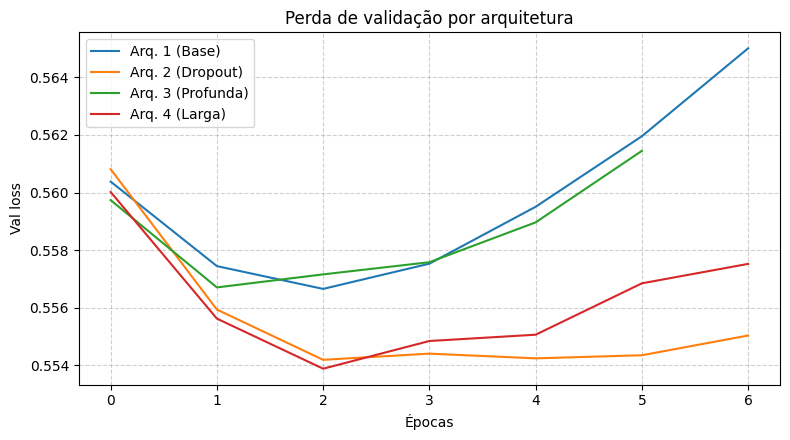

In [19]:
def avaliar(modelo, X_, y_):
    prob = modelo.predict(X_, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    return {'Acurácia': accuracy_score(y_, pred), 'Precision': precision_score(y_, pred),
            'Recall': recall_score(y_, pred), 'F1-Score': f1_score(y_, pred), 'AUC': roc_auc_score(y_, prob)}

linhas = {}
for nome, m in modelos.items():
    r = avaliar(m, X_val, y_val); h = historicos[nome].history; b = int(np.argmin(h['val_loss']))
    r['Acc. treino'] = h['accuracy'][b]; r['Gap (treino−val)'] = h['accuracy'][b] - h['val_accuracy'][b]
    r['Épocas'] = len(h['loss']); r['Parâmetros'] = m.count_params()
    linhas[nome] = r
df_comp = pd.DataFrame(linhas).T
print("--- TABELA COMPARATIVA (CONJUNTO DE VALIDAÇÃO, 15%) ---")
print(df_comp.round(4).to_string())

nome_escolhido = df_comp['F1-Score'].astype(float).idxmax()
modelo_escolhido, historico_escolhido = modelos[nome_escolhido], historicos[nome_escolhido]
print(f"\nModelo escolhido (maior F1 na validação): {nome_escolhido}")
if nome_escolhido != 'Arq. 4 (Larga)':
    print("Obs.: na divisão 70/15/15 a escolha diferiu da versão anterior (Arq. 4); vale a escolha atual, baseada na validação.")

# Baseline de referência (regressão logística, mesmos dados) — mostra se a MLP realmente agrega
lr = LogisticRegression(max_iter=300).fit(X_train, y_train)
p_lr = lr.predict_proba(X_val)[:, 1]
baseline_val = {'Acurácia': accuracy_score(y_val, p_lr > .5), 'F1-Score': f1_score(y_val, p_lr > .5), 'AUC': roc_auc_score(y_val, p_lr)}
print("\nReferência — Regressão Logística (validação):", {k: round(v, 4) for k, v in baseline_val.items()})

plt.figure(figsize=(8, 4.5))
for nome, hist in historicos.items():
    plt.plot(hist.history['val_loss'], label=nome)
plt.title('Perda de validação por arquitetura'); plt.xlabel('Épocas'); plt.ylabel('Val loss')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.6); plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, 'val_loss_arquiteturas.png'), dpi=130); plt.show()

### Análise e justificativa da escolha do modelo

**Resultados na validação (15%)** — todas as quatro arquiteturas ficaram muito próximas:

| Modelo | Acurácia | Precision | Recall | F1 | AUC | Gap treino−val. |
|---|---|---|---|---|---|---|
| Arq. 1 (Base) | 0,7132 | 0,7335 | 0,6698 | 0,7002 | 0,7876 | 0,0150 |
| **Arq. 2 (Dropout)** | **0,7169** | 0,7319 | **0,6845** | **0,7074** | 0,7893 | **0,0060** |
| Arq. 3 (Profunda) | 0,7139 | 0,7408 | 0,6581 | 0,6970 | 0,7872 | 0,0066 |
| Arq. 4 (Larga) | 0,7145 | 0,7354 | 0,6701 | 0,7012 | 0,7896 | 0,0080 |

**Por que a Arq. 2?** Ela teve o **maior F1 (0,7074)** — critério definido antes do experimento —, a **maior acurácia** e o **maior recall** (0,6845), isto é, deixou escapar menos roubos que as demais, mantendo precision praticamente igual (≈ 0,73). Além disso, apresentou o **menor gap treino−validação (0,006, contra 0,015 da Base)**: o Dropout de 0,3 impediu a rede de ajustar-se demais ao treino. A Arq. 2 tem exatamente os mesmos 40.321 parâmetros da Base, então o ganho vem da **regularização**, não de mais capacidade.

**O que cada alteração ensinou:**
- **Dropout (Arq. 1 → 2):** melhorou F1 em ≈ 0,7 p.p. e reduziu o gap — efeito pequeno, mas na direção esperada.
- **Mais camadas (Arq. 3):** *piorou* o F1 (0,6970). Mais profundidade não ajudou: o problema tem pouca interação complexa entre atributos.
- **Mais neurônios + Dropout 0,5 (Arq. 4):** praticamente empatou com a Base (F1 0,7012; AUC 0,7896, a mais alta por uma margem mínima de 0,0003) usando **4,6× mais parâmetros** — custo sem ganho.
- Todas pararam por *early stopping* entre as épocas 2 e 3: o modelo aprende o que há para aprender **rápido** e depois só passa a decorar.

**Ressalvas honestas.**
1. As diferenças entre arquiteturas são **pequenas (≤ 1,0 p.p. de F1)** e foram obtidas com **uma única semente**; é provável que parte delas seja ruído de inicialização. A escolha da Arq. 2 é defensável (melhor métrica + melhor regularização), mas não deve ser vendida como uma superioridade grande.
2. **Referência simples:** a regressão logística obteve F1 de 0,7154 (**maior** que o da Arq. 2), mas acurácia (0,7100) e AUC (0,7815) **menores**. Ou seja, a MLP é **ligeiramente melhor em acurácia e AUC** e **ligeiramente pior em F1** — na prática, um empate técnico. Isso indica que o sinal nos dados é essencialmente **aditivo** (cada atributo contribui de forma quase independente) e que o limite de desempenho vem da **informação disponível**, não da complexidade do modelo.
3. Mantemos a MLP por ser o objetivo do desafio e porque entrega probabilidades calibradas para a aplicação web, mas reconhecemos que, para este conjunto de atributos, ela não supera de forma relevante um modelo linear.

## 7. Avaliação final no **conjunto de teste (15%)**
Matriz de confusão, Curva ROC (AUC), *classification report* (precision, recall, F1 e acurácia) e curvas de treino/validação do modelo escolhido.

--- RELATÓRIO FINAL NO TESTE (15%): Arq. 2 (Dropout) ---
              precision    recall  f1-score   support

   Furto (0)     0.7036    0.7491    0.7257      8789
   Roubo (1)     0.7318    0.6845    0.7073      8788

    accuracy                         0.7168     17577
   macro avg     0.7177    0.7168    0.7165     17577
weighted avg     0.7177    0.7168    0.7165     17577

AUC (teste): 0.7922


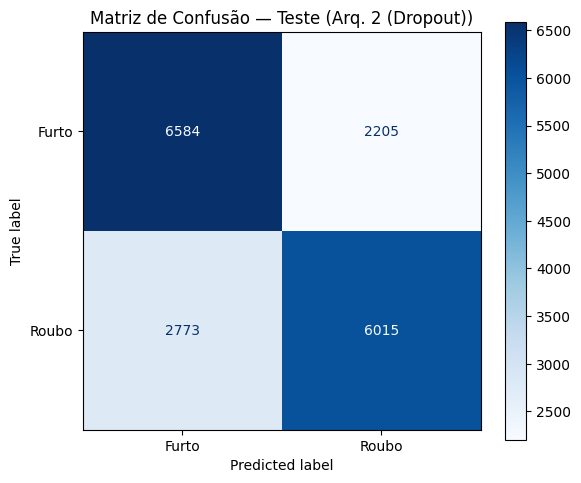

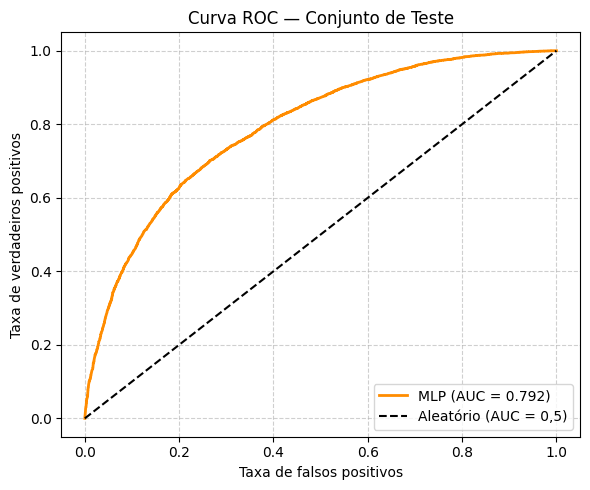

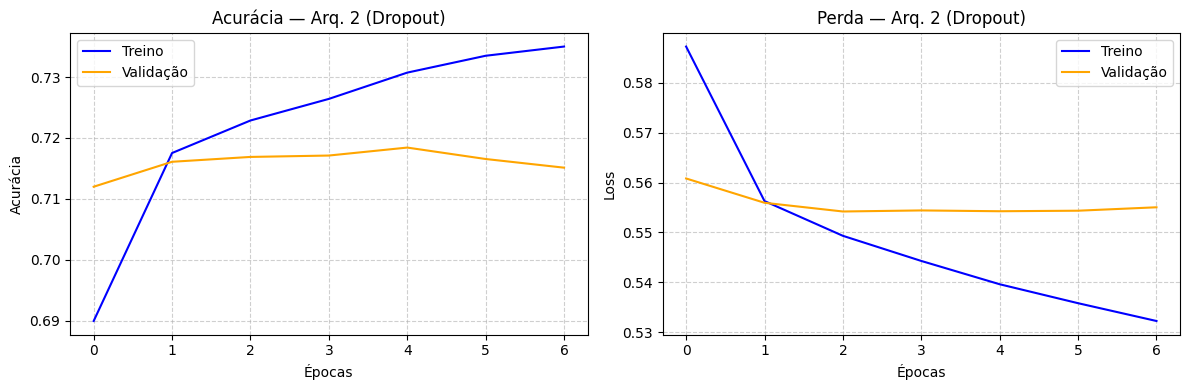

In [20]:
prob_test = modelo_escolhido.predict(X_test, verbose=0).ravel()
y_pred = (prob_test > 0.5).astype(int)

print(f"--- RELATÓRIO FINAL NO TESTE (15%): {nome_escolhido} ---")
print(classification_report(y_test, y_pred, target_names=['Furto (0)', 'Roubo (1)'], digits=4))
auc_teste = roc_auc_score(y_test, prob_test)
cm = confusion_matrix(y_test, y_pred)
print(f"AUC (teste): {auc_teste:.4f}")

# Matriz de confusão
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Furto', 'Roubo']).plot(cmap='Blues', values_format='d', ax=ax)
plt.title(f'Matriz de Confusão — Teste ({nome_escolhido})'); plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, 'matriz_confusao.png'), dpi=130); plt.show()

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, prob_test)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'MLP (AUC = {auc_teste:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatório (AUC = 0,5)')
plt.xlabel('Taxa de falsos positivos'); plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curva ROC — Conjunto de Teste'); plt.legend(loc='lower right'); plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout(); plt.savefig(os.path.join(FIGURAS, 'curva_roc.png'), dpi=130); plt.show()

# Curvas de treinamento/validação
h = historico_escolhido.history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(h['accuracy'], label='Treino', color='blue'); ax1.plot(h['val_accuracy'], label='Validação', color='orange')
ax1.set_title(f'Acurácia — {nome_escolhido}'); ax1.set_xlabel('Épocas'); ax1.set_ylabel('Acurácia'); ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.6)
ax2.plot(h['loss'], label='Treino', color='blue'); ax2.plot(h['val_loss'], label='Validação', color='orange')
ax2.set_title(f'Perda — {nome_escolhido}'); ax2.set_xlabel('Épocas'); ax2.set_ylabel('Loss'); ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout(); plt.savefig(os.path.join(FIGURAS, 'curvas_treinamento.png'), dpi=130); plt.show()

In [21]:
# Avaliação final com model.evaluate (perda e acurácia no conjunto de TESTE, 15%)
loss_teste, acc_teste_keras = modelo_escolhido.evaluate(X_test, y_test, verbose=0)
print(f"model.evaluate no TESTE -> perda (binary_crossentropy): {loss_teste:.4f} | acurácia: {acc_teste_keras:.4f}")
print(f"Para comparação, perda de validação no melhor ponto: {min(historico_escolhido.history['val_loss']):.4f}")

model.evaluate no TESTE -> perda (binary_crossentropy): 0.5502 | acurácia: 0.7168
Para comparação, perda de validação no melhor ponto: 0.5542


### Interpretação da avaliação final (teste, 15% — dados inéditos)

O conjunto de teste foi usado **uma única vez**, depois de a arquitetura já ter sido escolhida na validação. O modelo vencedor (**Arq. 2 — Dropout**) obteve:

| Classe | Precision | Recall | F1 | Suporte |
|---|---|---|---|---|
| Furto (0) | 0,7036 | 0,7491 | 0,7257 | 8.789 |
| Roubo (1) | 0,7318 | 0,6845 | 0,7073 | 8.788 |
| **Acurácia** | | | **0,7168** | 17.577 |

**AUC = 0,7922.** Como as classes estão balanceadas no teste (≈ 50/50), o acaso daria 50% de acurácia e AUC 0,5; o modelo está, portanto, **bem acima do acaso**, mas longe de ser um classificador definitivo.

**Leitura dos números:**
- **Generaliza bem:** acurácia no teste (0,7168) praticamente idêntica à da validação (0,7169) — diferença de 0,01 p.p. A escolha do modelo não "viciou" na validação.
- **Onde erra:** o modelo é **mais conservador com roubo**. Cerca de **31,5% dos roubos** (1 − 0,6845) são classificados como furto, contra cerca de **25,1% dos furtos** (1 − 0,7491) classificados como roubo. Em outras palavras, é mais fácil o modelo "subestimar" a violência do que "superestimá-la". Se a aplicação priorizasse não perder roubos, valeria **reduzir o limiar de decisão** abaixo de 0,5 (aceitando mais falsos alarmes) — decisão que depende do custo de cada tipo de erro.
- **Precision × recall:** ao apontar "roubo", o modelo acerta ≈ 73% das vezes (precision 0,73), mas captura ≈ 68% dos roubos reais (recall 0,68).
- **Curva ROC:** AUC 0,79 significa que, sorteando um roubo e um furto, o modelo atribui probabilidade maior de roubo ao roubo real em cerca de 79% dos pares.

**Overfitting/underfitting (seção 8):** gap treino−validação de apenas 0,006 e validação ≈ teste. Não há overfitting relevante; também não há subajuste evidente, pois aumentar a capacidade (Arq. 3 e 4) **não** trouxe ganho — o limite está na **informação dos atributos**, não na rede.

## 8. Overfitting / underfitting
Diagnóstico calculado a partir dos números do modelo escolhido (época de melhor `val_loss`): comparamos treino × validação e validação × teste.

In [22]:
b = int(np.argmin(h['val_loss']))
acc_tr, acc_va = h['accuracy'][b], h['val_accuracy'][b]
loss_tr, loss_va = h['loss'][b], h['val_loss'][b]
acc_te = accuracy_score(y_test, y_pred)
gap = acc_tr - acc_va

print(f"Época escolhida (EarlyStopping): {b+1} de {len(h['loss'])} executadas")
print(f"Acurácia  — treino: {acc_tr:.4f} | validação: {acc_va:.4f} | teste: {acc_te:.4f}")
print(f"Perda     — treino: {loss_tr:.4f} | validação: {loss_va:.4f}")
print(f"Gap treino−validação: {gap:+.4f} | validação−teste: {acc_va - acc_te:+.4f}")

if gap > 0.05:
    diag = "Sinais de OVERFITTING: o treino é bem melhor que a validação."
elif acc_va < 0.65 and gap < 0.03:
    diag = "Tendência a UNDERFITTING / limite de informação: treino e validação são parecidos e ambos moderados — os atributos disponíveis explicam apenas parte do rótulo."
else:
    diag = "Ajuste equilibrado: gap pequeno entre treino e validação (sem overfitting relevante)."
print("\nDiagnóstico:", diag)
if abs(acc_va - acc_te) < 0.02:
    print("Validação e teste concordam (<2 p.p.): a escolha do modelo generaliza para dados não vistos.")
else:
    print("Atenção: validação e teste diferem ≥2 p.p.; interpretar com cautela.")

Época escolhida (EarlyStopping): 3 de 7 executadas
Acurácia  — treino: 0.7229 | validação: 0.7169 | teste: 0.7168
Perda     — treino: 0.5493 | validação: 0.5542
Gap treino−validação: +0.0060 | validação−teste: +0.0001

Diagnóstico: Ajuste equilibrado: gap pequeno entre treino e validação (sem overfitting relevante).
Validação e teste concordam (<2 p.p.): a escolha do modelo generaliza para dados não vistos.


## 9. Salvando modelo, colunas, categorias e métricas
A aplicação web usa exatamente as **colunas e categorias do treino**; o relatório (slides) lê o `metricas.json`.

In [23]:
modelo_escolhido.save(os.path.join(ARTEFATOS, 'modelo_mlp.keras'))
with open(os.path.join(ARTEFATOS, 'colunas_treino.json'), 'w', encoding='utf-8') as f:
    json.dump(COLUNAS, f, ensure_ascii=False)

ordem_dia = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
cats_app = {a: list(c) for a, c in categorias.items()}
cats_app['DIA_SEMANA'] = [x for x in ordem_dia if x in cats_app['DIA_SEMANA']] + [x for x in cats_app['DIA_SEMANA'] if x not in ordem_dia]
with open(os.path.join(ARTEFATOS, 'categorias.json'), 'w', encoding='utf-8') as f:
    json.dump(cats_app, f, ensure_ascii=False)

rep = classification_report(y_test, y_pred, target_names=['Furto', 'Roubo'], output_dict=True)
metricas = {
    'fonte': 'SSP-SP — Celulares Subtraídos 2025 (https://www.ssp.sp.gov.br/estatistica/consultas)',
    'registros': {'originais': int(len(df)), 'sp_fato_linhas': int(n_sp_linhas), 'sp_um_por_bo': int(len(df_sp)),
                  'roubo_furto_sp': int(len(d)), 'base_balanceada': int(N), 'por_classe': int(n_classe),
                  'treino': int(len(df_treino)), 'validacao': int(len(df_val)), 'teste': int(len(df_teste))},
    'proporcoes': {k: round(float(v), 4) for k, v in prop.items()},
    'n_entradas': int(N_ENTRADA), 'atributos': ATRIBUTOS,
    'categorias_por_atributo': {a: len(c) for a, c in categorias.items()},
    'treino_config': {'otimizador': 'Adam', 'lr': LR, 'perda': 'binary_crossentropy', 'batch_size': BATCH,
                      'max_epocas': MAX_EPOCAS, 'early_stopping_paciencia': PACIENCIA, 'seed': SEED},
    'arquiteturas': {n: [list(x) for x in v] for n, v in ARQUITETURAS.items()},
    'comparativo_validacao': {n: {k: float(v) for k, v in r.items()} for n, r in linhas.items()},
    'baseline_regressao_logistica_val': {k: float(v) for k, v in baseline_val.items()},
    'modelo_escolhido': nome_escolhido,
    'teste': {'acuracia': float(acc_te), 'auc': float(auc_teste), 'matriz_confusao': cm.tolist(),
              'precision_furto': float(rep['Furto']['precision']), 'recall_furto': float(rep['Furto']['recall']), 'f1_furto': float(rep['Furto']['f1-score']),
              'precision_roubo': float(rep['Roubo']['precision']), 'recall_roubo': float(rep['Roubo']['recall']), 'f1_roubo': float(rep['Roubo']['f1-score']),
              'precision_macro': float(rep['macro avg']['precision']), 'recall_macro': float(rep['macro avg']['recall']), 'f1_macro': float(rep['macro avg']['f1-score'])},
    'diagnostico': {'epoca_melhor': b + 1, 'epocas_executadas': len(h['loss']), 'acc_treino': float(acc_tr), 'acc_val': float(acc_va),
                    'acc_teste': float(acc_te), 'loss_treino': float(loss_tr), 'loss_val': float(loss_va), 'gap': float(gap), 'texto': diag},
    'historico_escolhido': {k: [float(x) for x in v] for k, v in h.items()},
}
with open(os.path.join(ARTEFATOS, 'metricas.json'), 'w', encoding='utf-8') as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)
print(f"Salvos em '{ARTEFATOS}/': modelo_mlp.keras, colunas_treino.json, categorias.json, metricas.json e figuras/")

Salvos em 'artefatos/': modelo_mlp.keras, colunas_treino.json, categorias.json, metricas.json e figuras/


## 10. Conclusões, limitações e uso de IA generativa

### Conclusões

1. **Desempenho do modelo:** a MLP com Dropout alcançou 71,7% de acurácia, F1 macro de aproximadamente 0,72 e AUC de 0,79 no conjunto de teste. O resultado ficou acima do acaso (50%), demonstrando que as características disponíveis ajudam a diferenciar roubos e furtos, embora a classificação ainda apresente limitações.

2. **Características das ocorrências:** período do dia e tipo de local apresentaram as diferenças mais expressivas na análise exploratória. Roubos foram mais frequentes à noite, de madrugada e em situações de abordagem direta, enquanto furtos predominaram nos transportes coletivos e durante a manhã e a tarde.

3. **Comparação das arquiteturas:** a inclusão de Dropout trouxe uma pequena melhoria, enquanto redes mais profundas ou com mais neurônios não apresentaram ganhos relevantes. A regressão logística também obteve resultados semelhantes, indicando que aumentar a complexidade da rede não garante melhor desempenho.

4. **Qualidade da avaliação:** a divisão dos dados em 70% treino, 15% validação e 15% teste, junto ao pré-processamento realizado somente no treino, ajudou a evitar vazamento de informações. Os resultados de validação (71,69%) e teste (71,68%) foram praticamente iguais, indicando boa capacidade de generalização.

5. **Aplicação prática:** o modelo pode auxiliar na triagem e auditoria de boletins de ocorrência, sinalizando registros para revisão humana. Entretanto, cerca de 31,5% dos roubos não foram identificados corretamente. Portanto, não é adequado para decisões automáticas ou para definir estratégias de policiamento.

### Limitações

- **Balanceamento:** a base foi ajustada para 50% de cada classe, diferente da distribuição real das ocorrências.
- **Atributos:** as informações disponíveis não permitem distinguir todos os casos.
- **Dados:** foram utilizados apenas registros de 2025 relacionados à subtração de celulares.
- **Categorias raras:** bairros e logradouros pouco frequentes foram agrupados em `OUTROS`.
- **Variação:** foi utilizada uma única semente de treinamento, sendo recomendável repetir os experimentos para verificar a estabilidade dos resultados.

O modelo classifica ocorrências já registradas ou hipotéticas, mas não prevê a ocorrência de crimes.

### Uso de IA generativa

Usamos o Claude como apoio na depuração, na escrita e na revisão do código e dos dados (o que levou a identificar o vazamento no período do dia) e nos ajustes do pipeline. Os resultados foram executados e conferidos pela equipe.